In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully")

In [ ]:
import glob
import pandas as pd

# Search both Kaggle and Colab default directories
files = glob.glob('/kaggle/input/**/*.csv', recursive=True) + glob.glob('/content/**/*.csv', recursive=True)

print("Available files:", files)

file_path = None

for file in files:
    try:
        temp = pd.read_csv(file, nrows=5)
        if 'Diabetes_binary' in temp.columns or 'insurance' in file:
            file_path = file
            break
    except Exception as e:
        continue

if file_path is None:
    if len(files) > 0:
        file_path = files[0]
        print(f"Diabetes_binary not found. Falling back to using the first available file: {file_path}")
    else:
        raise ValueError("No CSV files found in the dataset directories.")

df = pd.read_csv(file_path)

print("Dataset loaded successfully from:", file_path)
print(df.head())

Available files: ['/content/insurance.csv', '/content/sample_data/mnist_test.csv', '/content/sample_data/mnist_train_small.csv', '/content/sample_data/california_housing_test.csv', '/content/sample_data/california_housing_train.csv']
Dataset loaded successfully from: /content/insurance.csv
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (1338, 7)

Column Names:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Statistical Description:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

df = df.dropna()

print("After Cleaning:", df.shape)

print("Missing Values:")
print(df.isnull().sum())

Duplicate Rows: 1
After Cleaning: (1337, 7)
Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


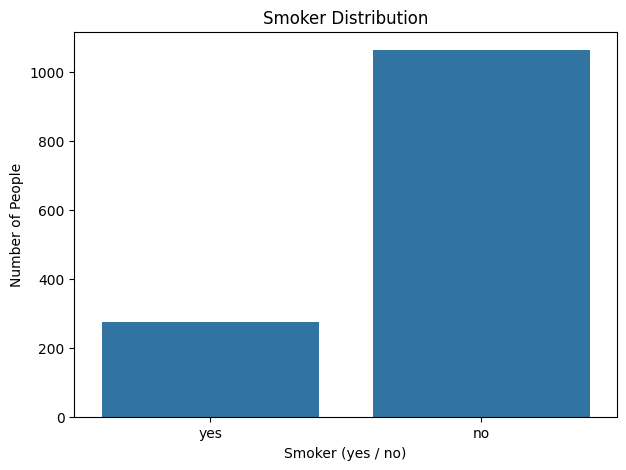

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

# Using 'smoker' instead of 'Diabetes_binary' as we are working with the insurance dataset
sns.countplot(x='smoker', data=df)

plt.title("Smoker Distribution")

plt.xlabel("Smoker (yes / no)")

plt.ylabel("Number of People")

plt.show()

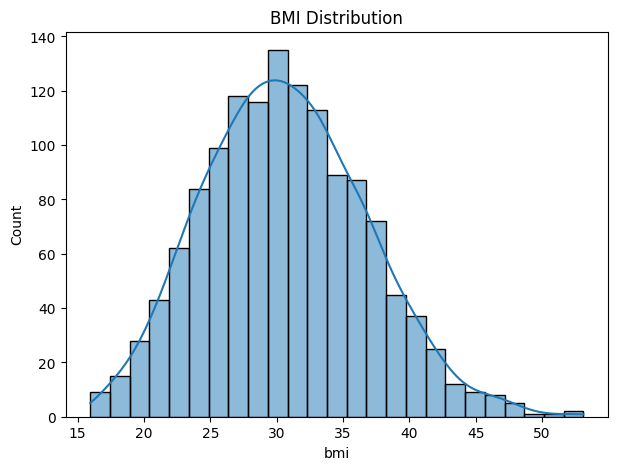

In [ ]:
plt.figure(figsize=(7,5))

# Using lowercase 'bmi' as it is written in the dataset columns
sns.histplot(df['bmi'], kde=True)

plt.title("BMI Distribution")

plt.show()

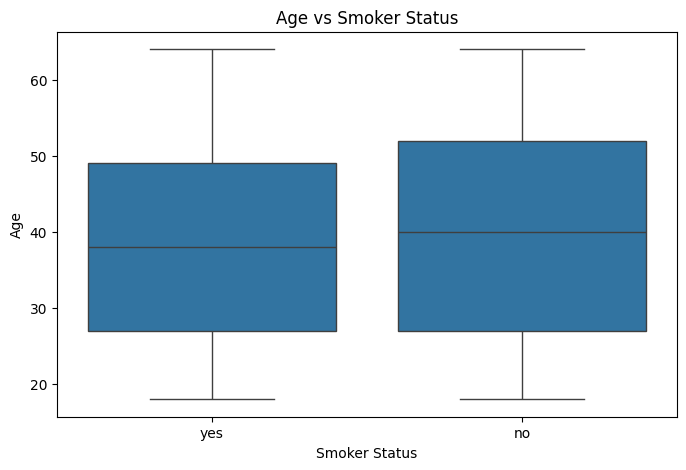

In [ ]:
plt.figure(figsize=(8,5))

# Using lowercase 'age' and active column 'smoker' from the insurance dataset
sns.boxplot(x='smoker', y='age', data=df)

plt.title("Age vs Smoker Status")

plt.xlabel("Smoker Status")

plt.ylabel("Age")

plt.show()

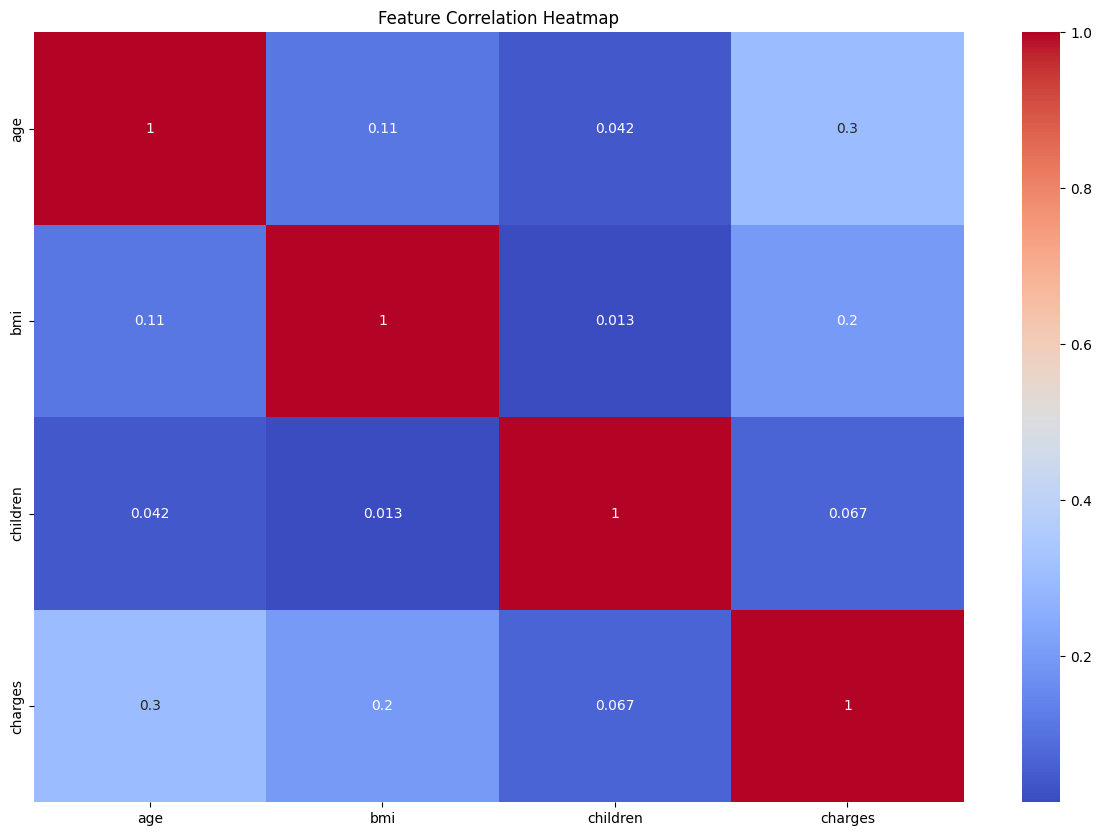

In [ ]:
plt.figure(figsize=(15,10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap='coolwarm',
    annot=True
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
# Separate features and target from the active insurance dataset
# Using 'smoker' as our binary target variable for classification
X = df.drop('smoker', axis=1)
y = df['smoker']

print("Input Features:", X.shape)
print("Target:", y.shape)

Input Features: (1337, 6)
Target: (1337,)


In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
import pandas as pd

# Convert categorical text columns (like sex and region) to numeric dummy variables
X_encoded = pd.get_dummies(X, drop_first=True)

# We have fewer than 15 features, so we set k to a valid number (e.g., 4)
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=4
)

X_selected = selector.fit_transform(X_encoded, y)

selected_features = X_encoded.columns[selector.get_support()]

print("Selected Features:")
print(selected_features.tolist())

Selected Features:
['age', 'charges', 'region_northwest', 'region_southwest']


Train-test splitting


In [ ]:
from sklearn.model_selection import train_test_split

# Splitting using X_encoded to ensure all categorical text columns are in numerical format
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1069, 8)
Testing Data: (268, 8)


In [ ]:
def create_pipeline(model):

    return Pipeline([
        ('scaler', StandardScaler()),

        ('feature_selection',
         SelectKBest(mutual_info_classif, k=15)),

        ('model', model)
    ])

Implementation of different ML and DL models


Logistic Regression



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Redefine create_pipeline with k=5 to avoid ValueError since we only have 8 features
def create_pipeline(model):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('feature_selection', SelectKBest(mutual_info_classif, k=5)),
        ('model', model)
    ])

lr_model = create_pipeline(
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    )
)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Completed")

Logistic Regression Completed


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = create_pipeline(
    DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    )
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Completed")

Decision Tree Completed


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = create_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Completed")

Random Forest Completed


In [ ]:
from sklearn.svm import SVC

svm_model = create_pipeline(
    SVC(
        kernel='linear',
        class_weight='balanced',
        random_state=42
    )
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Completed")

SVM Completed


In [ ]:
from sklearn.neural_network import MLPClassifier
import numpy as np

# Map target string labels 'yes'/'no' to numeric 1/0 to fix MLP validation calculation
y_train_num = y_train.map({'yes': 1, 'no': 0})
y_test_num = y_test.map({'yes': 1, 'no': 0})

ann_model = create_pipeline(
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=30,
        early_stopping=True,
        random_state=42
    )
)

ann_model.fit(X_train, y_train_num)

# Predict numeric labels and map back to strings to remain consistent with previous models
ann_pred_num = ann_model.predict(X_test)
ann_pred = np.where(ann_pred_num == 1, 'yes', 'no')

print("ANN Model Completed")

ANN Model Completed


Hybrid ML/DL model – Random Forest + ANN Model name: RF-ANN Hybrid Ensemble


In [ ]:
from sklearn.ensemble import VotingClassifier
import numpy as np

# Base models for the hybrid ensemble
rf_base = create_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
)

ann_base = create_pipeline(
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        max_iter=30,
        early_stopping=True,
        random_state=42
    )
)

# Voting Classifier
hybrid_model = VotingClassifier(
    estimators=[
        ('Random_Forest', rf_base),
        ('ANN', ann_base)
    ],
    voting='soft'
)

# We train using numeric labels to satisfy MLPClassifier's string constraints
hybrid_model.fit(X_train, y_train_num)

# Predict and map numeric predictions back to original string classes ('yes' / 'no')
hybrid_pred_num = hybrid_model.predict(X_test)
hybrid_pred = np.where(hybrid_pred_num == 1, 'yes', 'no')

print("Hybrid RF-ANN Model Completed")

Hybrid RF-ANN Model Completed


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    'Logistic Regression': (lr_model, lr_pred),
    'Decision Tree': (dt_model, dt_pred),
    'Random Forest': (rf_model, rf_pred),
    'SVM': (svm_model, svm_pred),
    'ANN': (ann_model, ann_pred),
    'Hybrid RF-ANN': (hybrid_model, hybrid_pred)
}

results = []

for name, (model, pred) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(
            y_test, pred, pos_label='yes', zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred, pos_label='yes', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, pred, pos_label='yes', zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9664     0.8710  0.9818    0.9231
1        Decision Tree    0.9590     0.8929  0.9091    0.9009
2        Random Forest    0.9664     0.9423  0.8909    0.9159
3                  SVM    0.9739     0.8871  1.0000    0.9402
4                  ANN    0.9291     0.9091  0.7273    0.8081
5        Hybrid RF-ANN    0.9664     0.9600  0.8727    0.9143


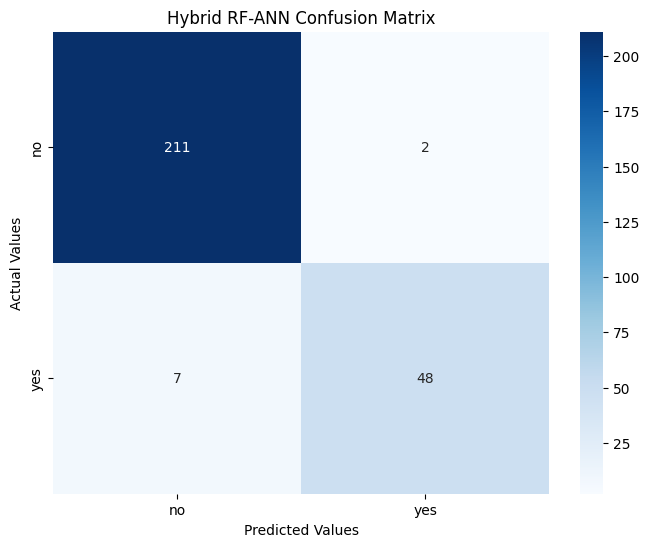

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

# We explicitly provide the class labels to ensure correct sorting/alignment in the matrix
cm = confusion_matrix(y_test, hybrid_pred, labels=['no', 'yes'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['no', 'yes'],
    yticklabels=['no', 'yes']
)

plt.title("Hybrid RF-ANN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

Compare all models

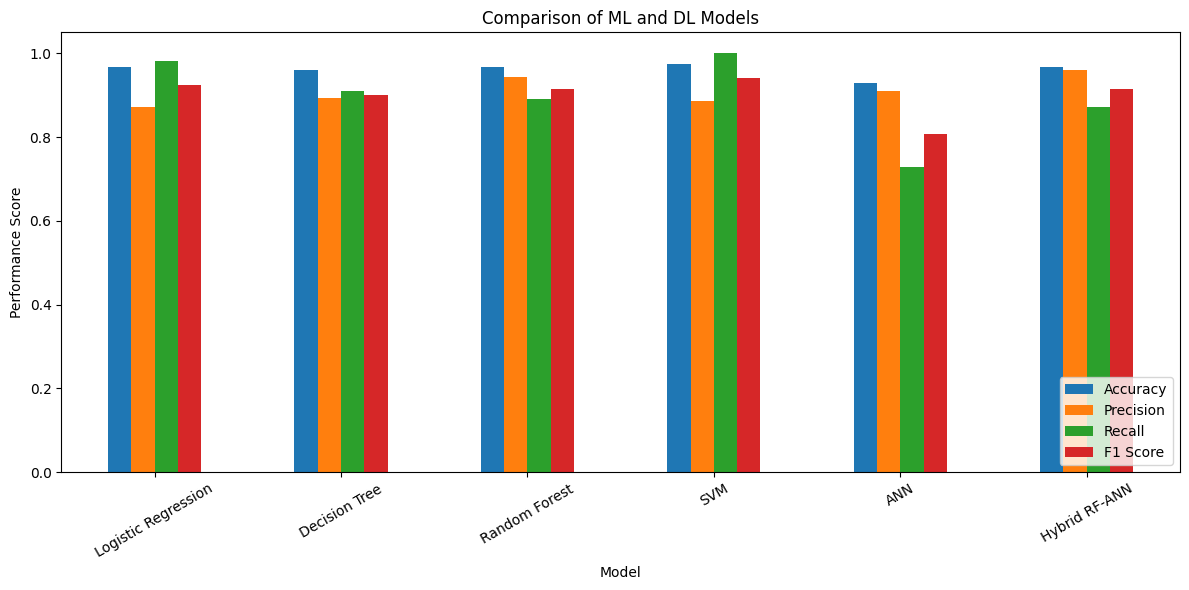

In [ ]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Comparison of ML and DL Models")

plt.ylabel("Performance Score")

plt.xticks(rotation=30)

plt.legend(loc='lower right')

plt.tight_layout()

plt.show()

Display classification report


In [ ]:
from sklearn.metrics import classification_report

print("Hybrid RF-ANN Classification Report")

# Using correct target class names representing smoking status
print(
    classification_report(
        y_test,
        hybrid_pred,
        target_names=['Non-Smoker', 'Smoker'],
        zero_division=0
    )
)

Hybrid RF-ANN Classification Report
              precision    recall  f1-score   support

  Non-Smoker       0.97      0.99      0.98       213
      Smoker       0.96      0.87      0.91        55

    accuracy                           0.97       268
   macro avg       0.96      0.93      0.95       268
weighted avg       0.97      0.97      0.97       268



All model confusion matrices

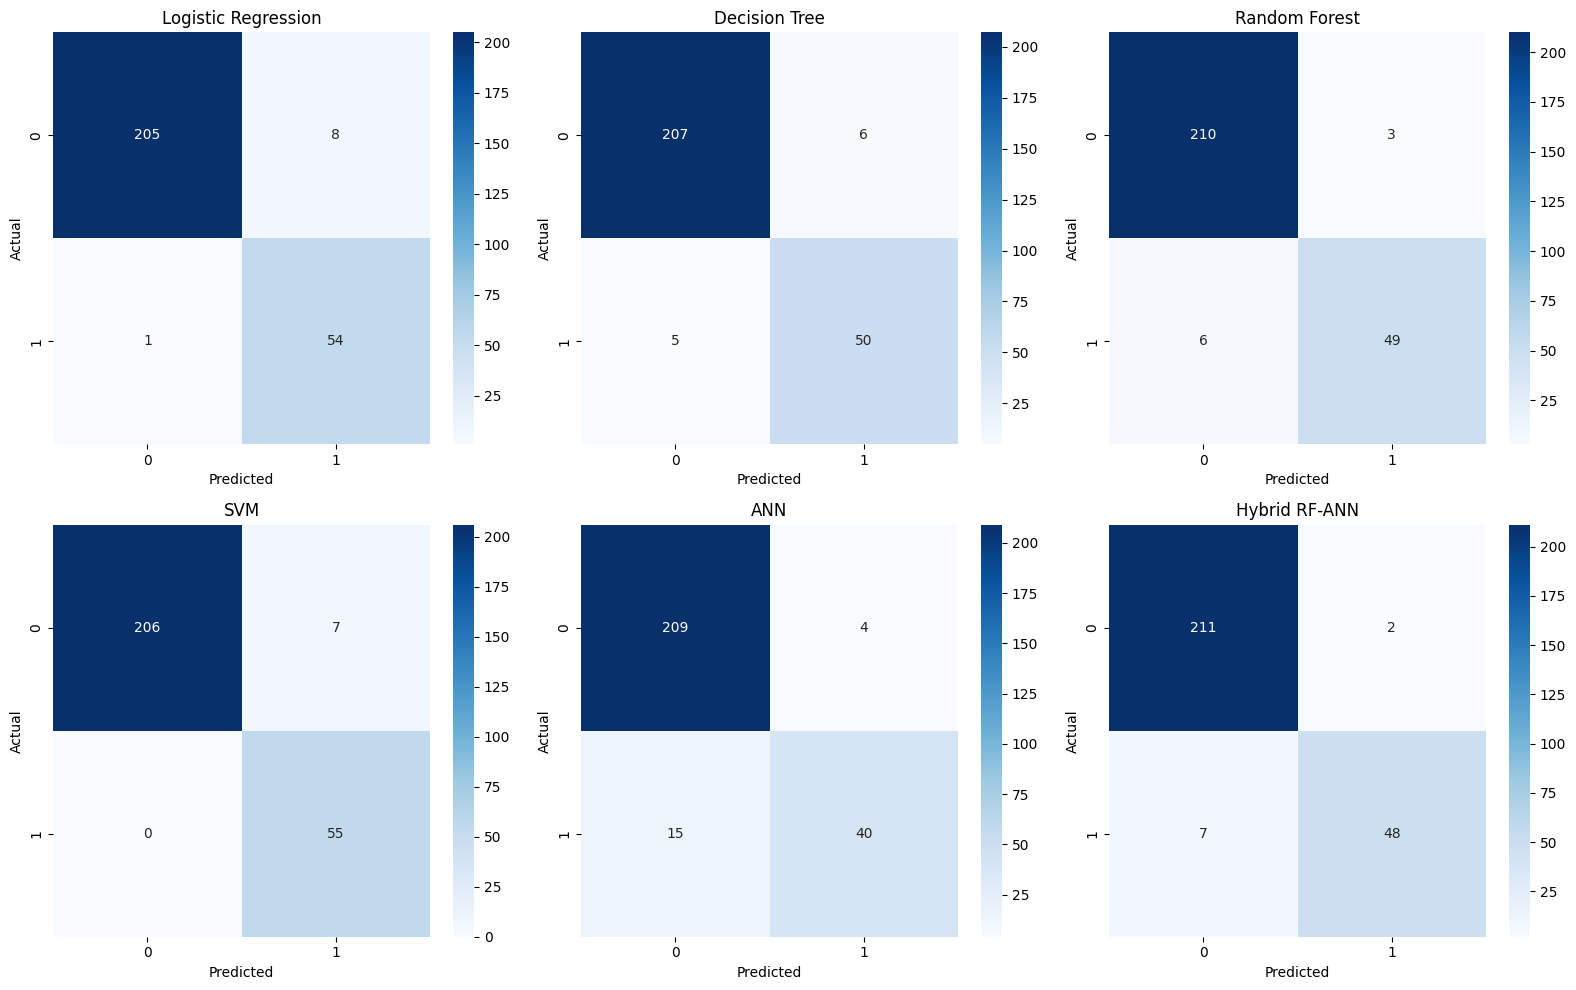

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, (model, pred)) in zip(axes.flat, models.items()):

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()